<a href="https://colab.research.google.com/github/braaaaayaaaaan/6001CMD_CW2_Group20/blob/main/PartB_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Part B - Exploratory Data Analysis

**Target:** Fully Paid (0) or Charged Off (1). Prediction is assumed to take place at loan issuance, after loan terms have been set.

This notebook selects the original attributes, filters resolved loans issued from 2007–2017, exports `selected_features.csv`, and performs basic EDA.

## 1. Load the dataset


In [ ]:
from pathlib import Path
import shutil
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from google.colab import drive

# Mount Google Drive and locate the complete CSV
drive.mount('/content/drive')
DRIVE_PATH = Path('/content/drive/MyDrive/ML_Group/loan.csv')
DATA_PATH = Path('/content/loan.csv')
OUT = Path('/content/part_b_outputs')
OUT.mkdir(parents=True, exist_ok=True)

# Copy the complete file before reading it
if not DRIVE_PATH.is_file():
    raise FileNotFoundError(f'CSV not found: {DRIVE_PATH}')

print('Drive CSV size (MB):', round(DRIVE_PATH.stat().st_size / 1024**2, 1))
shutil.copy2(DRIVE_PATH, DATA_PATH)
print('Local CSV size (MB):', round(DATA_PATH.stat().st_size / 1024**2, 1))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive CSV size (MB): 1134.3
Local CSV size (MB): 1134.3


## 2. Initial feature selection
The initial attributes were selected based on their relevance to loan details, borrower income and credit history.

`loan_status` is the target. `issue_d` and `earliest_cr_line` are retained for filtering and possible feature engineering. Post-issuance payment information and identifiers are excluded from predictors to reduce data leakage.

In [ ]:
# Main loan and borrower attributes
CORE = [
    'loan_amnt','term','int_rate','installment','purpose','annual_inc','dti',
    'emp_length','home_ownership','verification_status','inq_last_6mths',
    'open_acc','total_acc','revol_util','revol_bal','delinq_2yrs',
    'pub_rec_bankruptcies','mths_since_last_delinq'
]

# Additional credit-related attributes for EDA
ADDITIONAL = [
    'pub_rec','mort_acc','grade','sub_grade','funded_amnt','funded_amnt_inv',
    'acc_open_past_24mths','bc_open_to_buy','mo_sin_rcnt_tl','num_il_tl',
    'pct_tl_nvr_dlq','total_bal_ex_mort','total_bc_limit','open_il_12m',
    'il_util','inq_fi'
]

# Target and date attributes used for filtering or analysis
ADMIN = ['loan_status','issue_d','earliest_cr_line']
SELECTED = ADMIN + CORE + ADDITIONAL

# Save the original attribute names for reference
columns = pd.read_csv(DATA_PATH, nrows=0).columns
pd.DataFrame({'attribute': columns}).to_csv(OUT / 'original_attributes.csv', index=False)
print('Original attributes:', len(columns))
print('Selected attributes:', len(SELECTED))

Original attributes: 145
Selected attributes: 37


## 3. Filter resolved loans and export selected attributes
Only loans issued between 2007 and 2017 with a final Fully Paid or Charged Off status are included.

In [ ]:
# Read only the selected attributes
raw = pd.read_csv(DATA_PATH, usecols=SELECTED, low_memory=False)
print('Original records:', f'{len(raw):,}')

# Filter by issuance year and final loan outcome
issue_year = pd.to_datetime(raw['issue_d'], format='%b-%Y', errors='coerce').dt.year
df = raw.loc[
    issue_year.between(2007, 2017) &
    raw['loan_status'].isin(['Fully Paid', 'Charged Off'])
].copy()
del raw

# Export the selected raw dataset
selected_csv = OUT / 'selected_features.csv'
df[SELECTED].to_csv(selected_csv, index=False)

# Add analysis-only columns after export
df['target'] = df['loan_status'].eq('Charged Off').astype(int)
print('Eligible records:', f'{len(df):,}')
print('Exported:', selected_csv)
display(df['loan_status'].value_counts())

Original records: 2,260,668
Eligible records: 1,256,425
Exported: /content/part_b_outputs/selected_features.csv


,count
loan_status,
Fully Paid,1001712
Charged Off,254713


## 4. Descriptive statistics and class distribution

,count,percent
loan_status,,
Fully Paid,1001712,79.73
Charged Off,254713,20.27


,count,mean,std,min,25%,50%,75%,max
loan_amnt,1256425.0,14397.27,8638.93,500.00,8000.00,12000.00,20000.00,40000.00
int_rate,1256425.0,13.25,4.73,5.32,9.75,12.79,15.99,30.99
installment,1256425.0,437.81,259.75,4.93,249.56,375.49,578.71,1719.83
annual_inc,1256425.0,76018.09,69697.66,0.00,45747.00,65000.00,90000.00,10999200.00
dti,1256225.0,18.25,10.51,-1.00,11.85,17.64,24.04,999.00
inq_last_6mths,1256424.0,0.66,0.95,0.00,0.00,0.00,1.00,8.00
open_acc,1256425.0,11.60,5.45,0.00,8.00,11.00,14.00,90.00
total_acc,1256425.0,25.05,11.96,2.00,16.00,23.00,32.00,176.00
revol_util,1255678.0,52.39,24.33,0.00,34.20,52.80,71.10,892.30
revol_bal,1256425.0,16306.22,22311.24,0.00,6021.00,11211.00,19828.00,2904836.00


,count,unique,top,freq
term,1256425,2,36 months,954389
purpose,1256425,14,debt_consolidation,733613
emp_length,1185033,11,10+ years,412639
home_ownership,1256425,6,MORTGAGE,621514
verification_status,1256425,3,Source Verified,484796
grade,1256425,7,B,367339
sub_grade,1256425,35,C1,80183


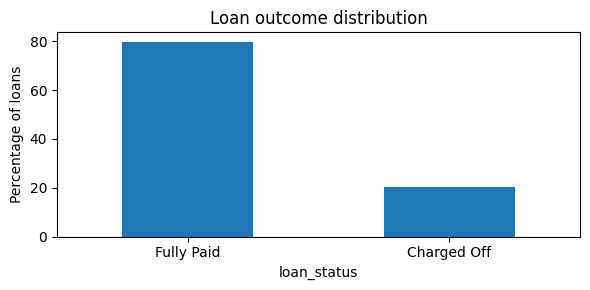

In [ ]:
# Identify numerical and categorical candidate attributes
categorical = ['term', 'purpose', 'emp_length', 'home_ownership',
               'verification_status', 'grade', 'sub_grade']
numeric = [col for col in CORE + ADDITIONAL if col not in categorical]

# Convert numerical values for analysis only
for col in numeric:
    df[col] = pd.to_numeric(df[col].astype(str).str.replace('%', '', regex=False), errors='coerce')

# Show class counts and percentages
class_table = df['loan_status'].value_counts().to_frame('count')
class_table['percent'] = class_table['count'] / len(df) * 100
display(class_table.round(2))
class_table.to_csv(OUT / 'class_distribution.csv')

# Summarise all numerical and categorical attributes
stats = df[numeric].describe().T
cat_stats = df[categorical].describe().T
display(stats.round(2))
display(cat_stats)
stats.to_csv(OUT / 'descriptive_statistics_numeric.csv')
cat_stats.to_csv(OUT / 'descriptive_statistics_categorical.csv')

# Plot the loan outcome distribution
class_table['percent'].plot.bar(figsize=(6, 3), rot=0, title='Loan outcome distribution')
plt.ylabel('Percentage of loans')
plt.tight_layout()
plt.savefig(OUT / 'class_distribution.png', dpi=150)
plt.show()

## 5. Missing value analysis
Calculate missing counts and percentages for all 34 candidate predictors. The chart also shows all predictors, including those with no missing values.

,count,percent
il_util,863094,68.69
open_il_12m,804062,64.00
inq_fi,804062,64.00
mths_since_last_delinq,631706,50.28
emp_length,71392,5.68
pct_tl_nvr_dlq,67680,5.39
mo_sin_rcnt_tl,67527,5.37
num_il_tl,67527,5.37
bc_open_to_buy,59846,4.76
mort_acc,47281,3.76


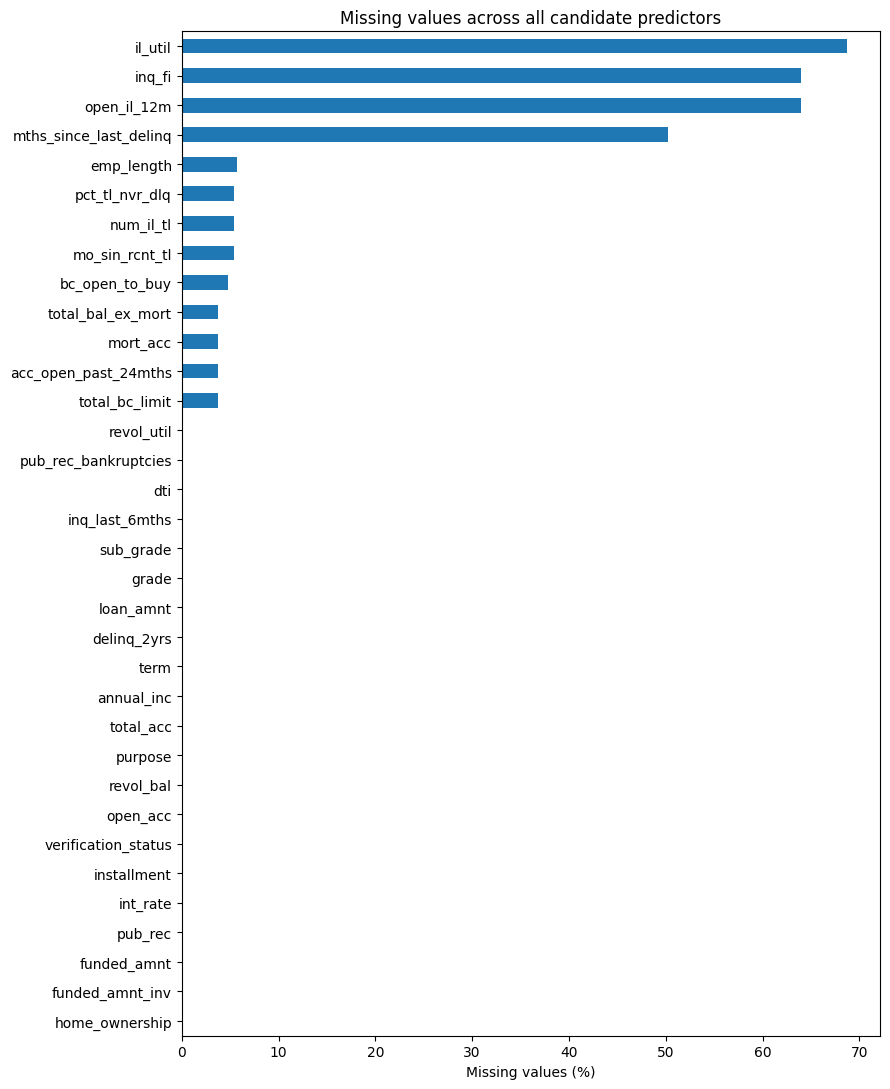

In [ ]:
# Check missing values in all candidate predictors
missing = pd.DataFrame({
    'count': df[CORE + ADDITIONAL].isna().sum(),
    'percent': df[CORE + ADDITIONAL].isna().mean() * 100
}).sort_values('percent', ascending=False)
display(missing.round(2))
missing.to_csv(OUT / 'missing_values.csv')

# Plot missing percentages for every candidate predictor
missing['percent'].sort_values().plot.barh(figsize=(9, 11))
plt.xlabel('Missing values (%)')
plt.title('Missing values across all candidate predictors')
plt.tight_layout()
plt.savefig(OUT / 'missing_values.png', dpi=150)
plt.show()

## 6. Feature distributions
Review distributions for every numerical and categorical candidate predictor.

Numerical attributes use percentiles and histograms.

Categorical attributes use full frequency tables and bar charts.

Histograms use the 1st–99th percentile for display only; full values remain in the tables and dataset.

,0.01,0.25,0.50,0.75,0.95,0.99
loan_amnt,1600.00,8000.00,12000.00,20000.00,32200.00,35000.00
int_rate,5.32,9.75,12.79,15.99,21.99,26.30
installment,54.13,249.56,375.49,578.71,956.84,1218.61
annual_inc,18000.00,45747.00,65000.00,90000.00,155000.00,250000.00
dti,1.87,11.85,17.64,24.04,32.86,38.15
inq_last_6mths,0.00,0.00,0.00,1.00,3.00,4.00
open_acc,3.00,8.00,11.00,14.00,22.00,29.00
total_acc,5.00,16.00,23.00,32.00,47.00,61.00
revol_util,1.40,34.20,52.80,71.10,91.61,98.30
revol_bal,212.00,6021.00,11211.00,19828.00,43300.00,94238.04


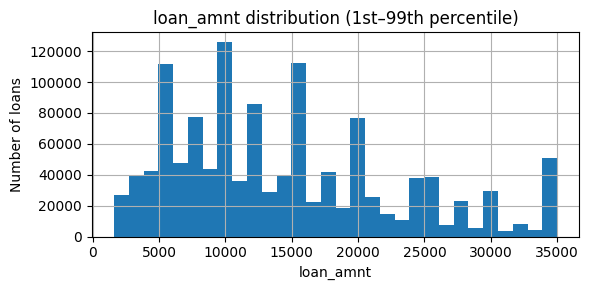

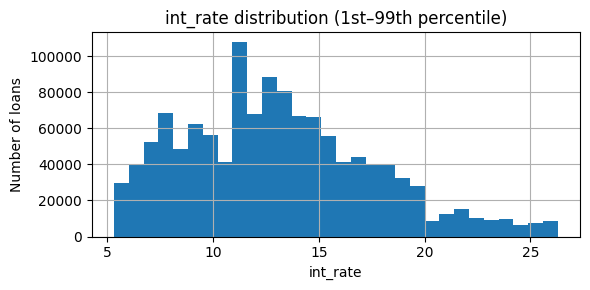

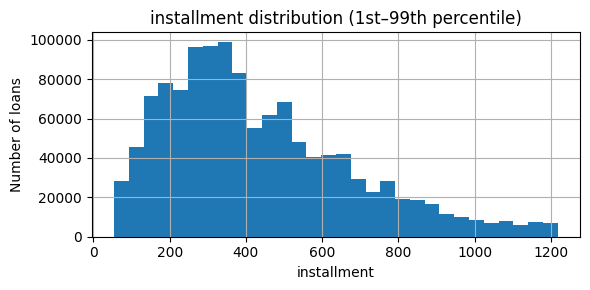

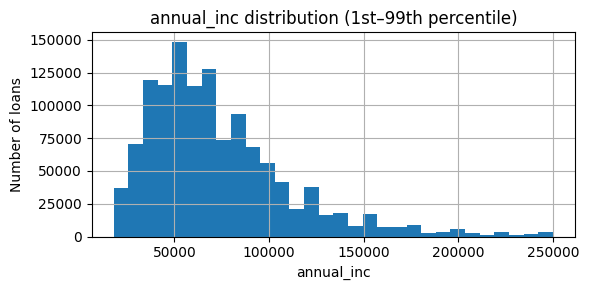

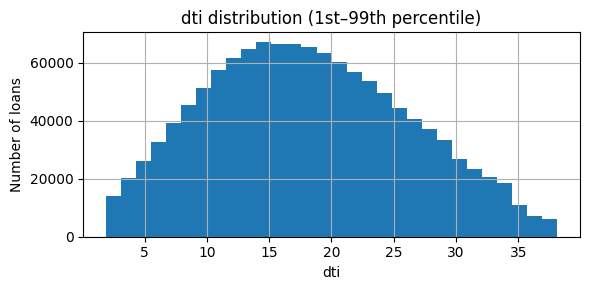

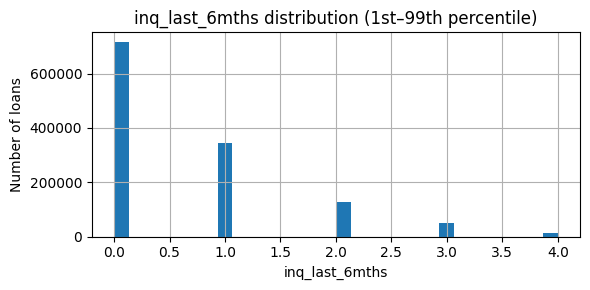

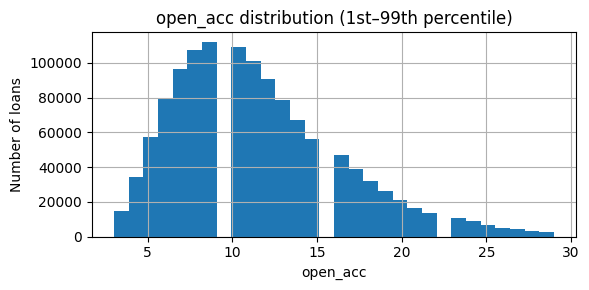

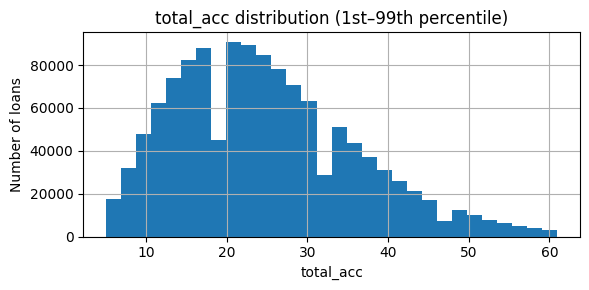

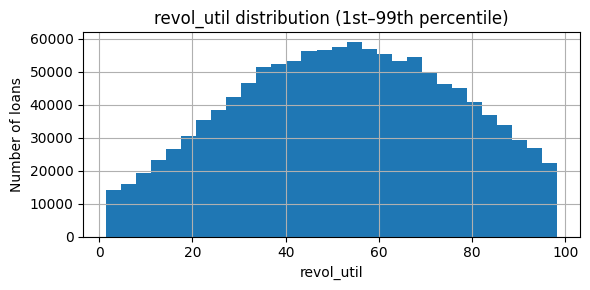

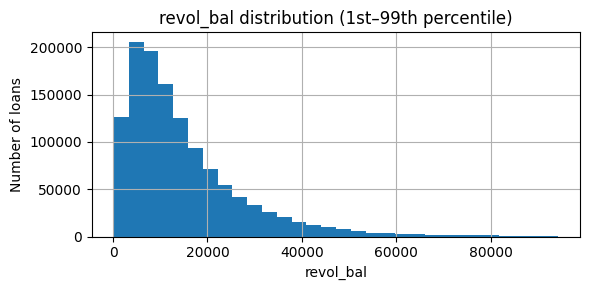

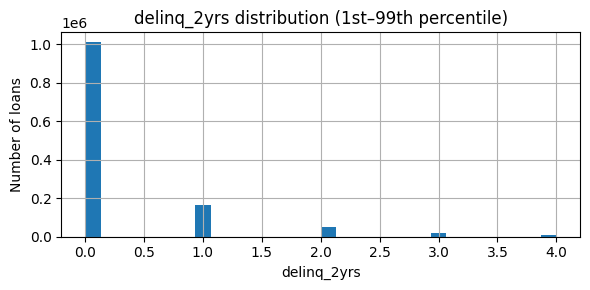

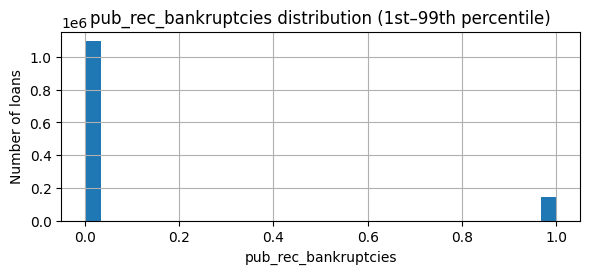

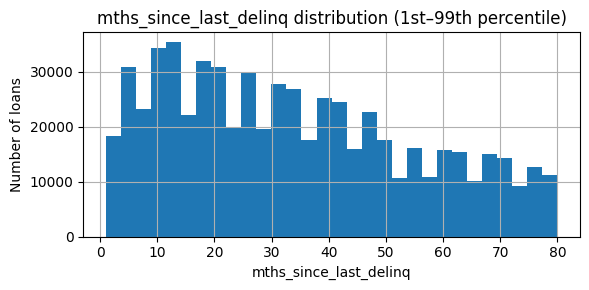

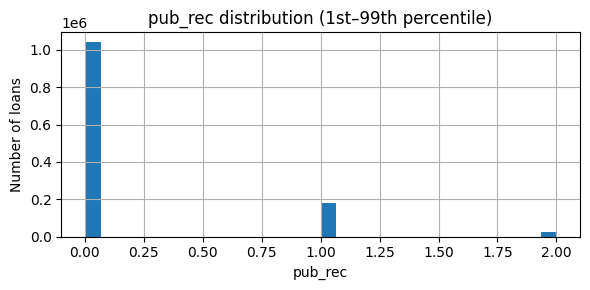

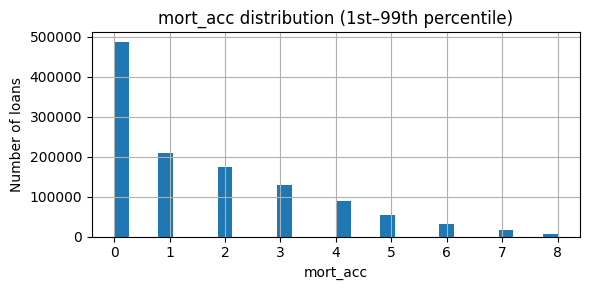

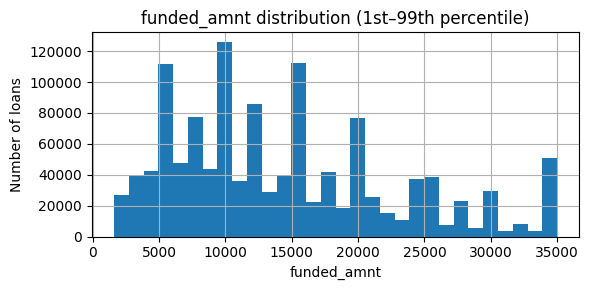

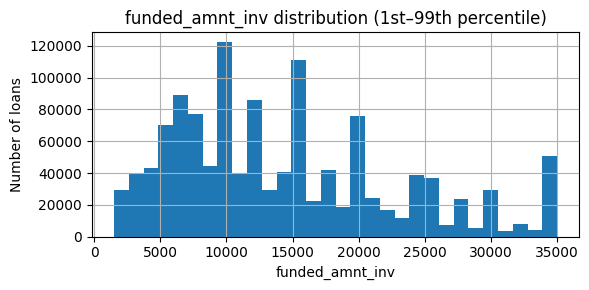

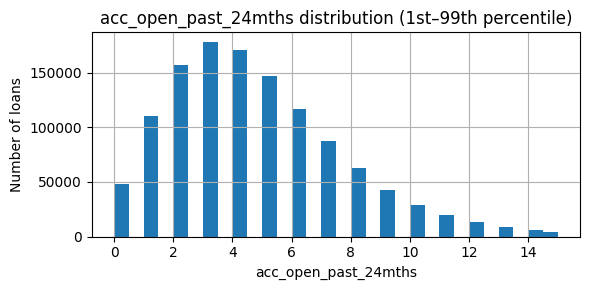

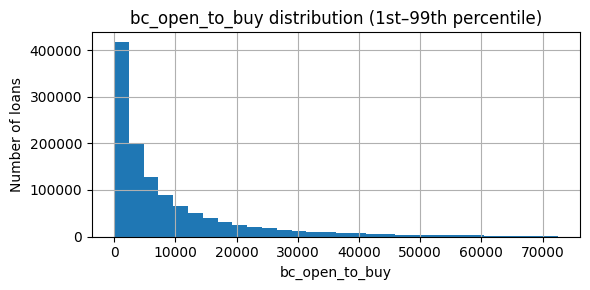

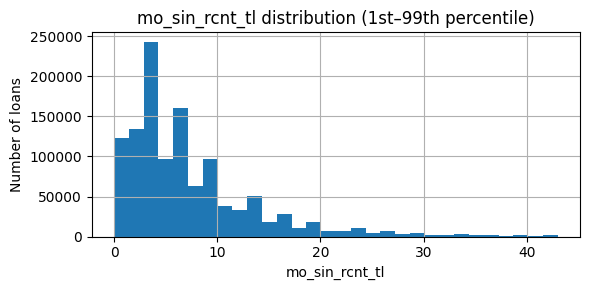

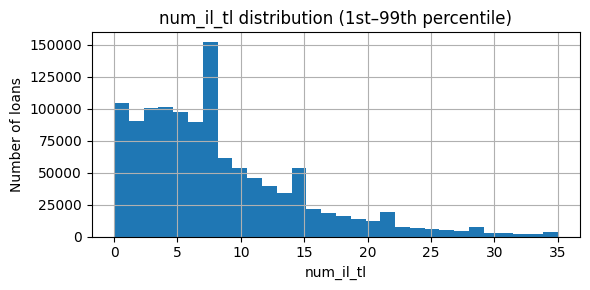

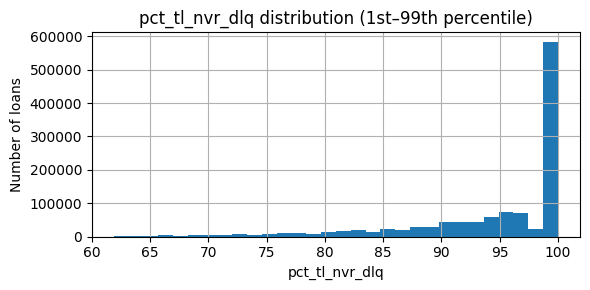

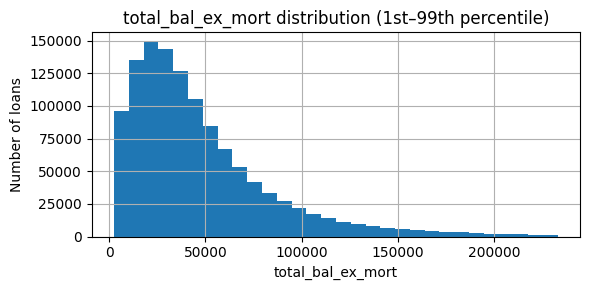

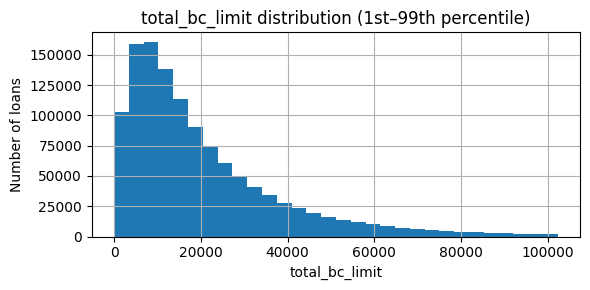

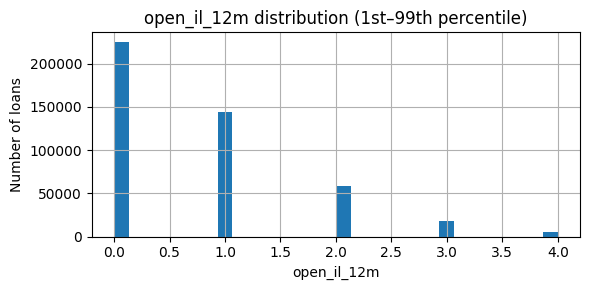

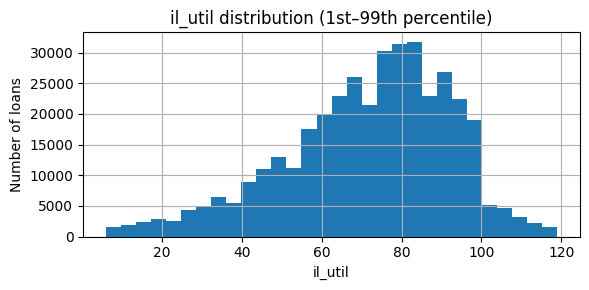

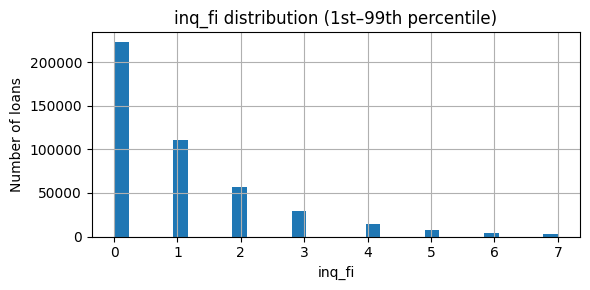

term: 2 categories


,count
term,
36 months,954389
60 months,302036


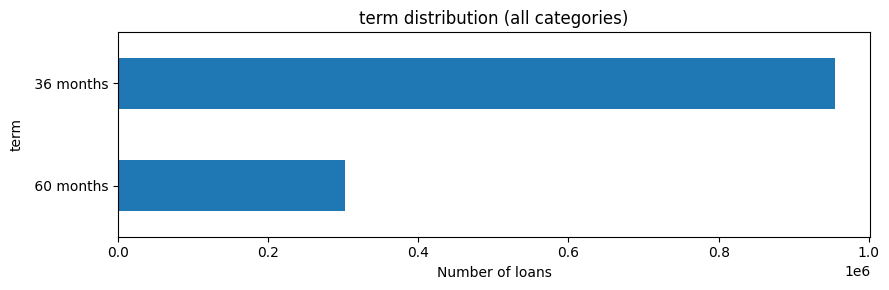

purpose: 14 categories


,count
purpose,
debt_consolidation,733613
credit_card,276295
home_improvement,80665
other,70349
major_purchase,26802
small_business,14520
medical,14117
car,13440
moving,8744


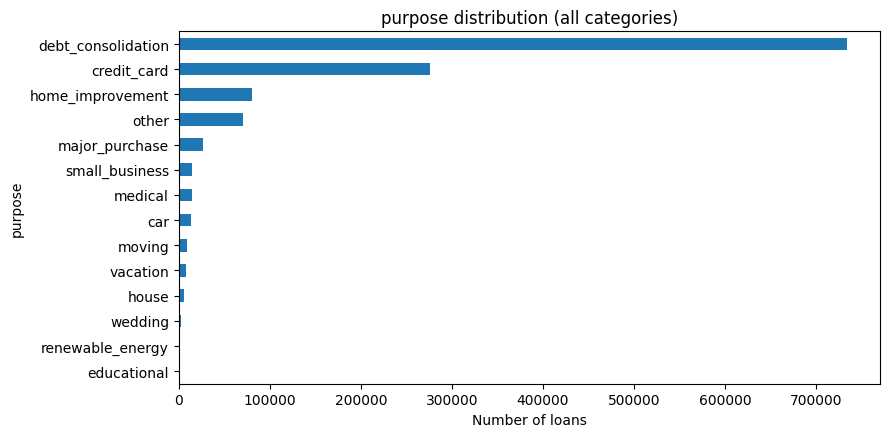

emp_length: 12 categories


,count
emp_length,
10+ years,412639
2 years,113623
< 1 year,100988
3 years,100354
1 year,82676
5 years,78703
4 years,74999
Missing,71392
6 years,58851


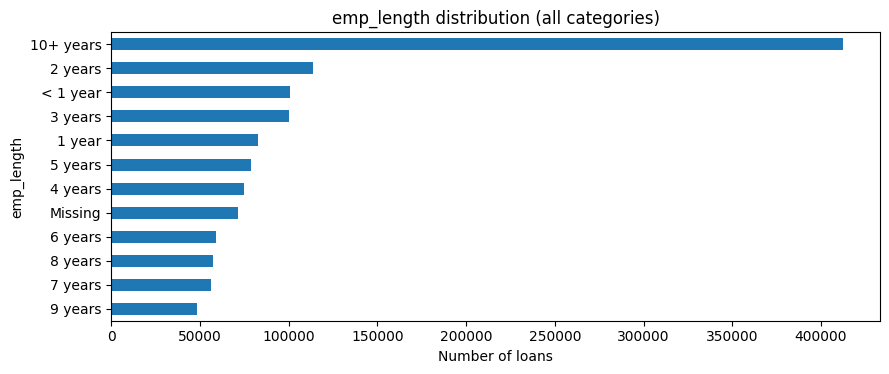

home_ownership: 6 categories


,count
home_ownership,
MORTGAGE,621514
RENT,500982
OWN,133485
ANY,252
OTHER,144
NONE,48


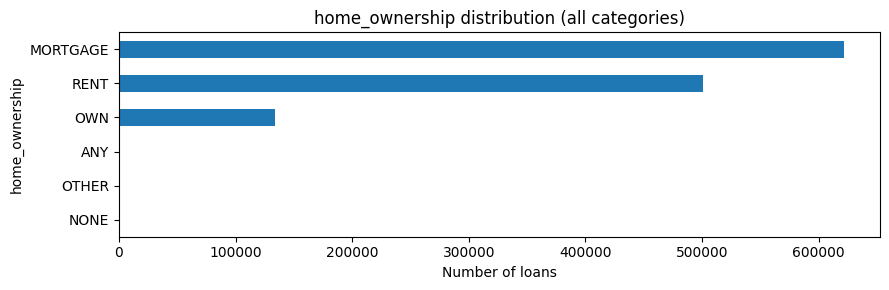

verification_status: 3 categories


,count
verification_status,
Source Verified,484796
Verified,396909
Not Verified,374720


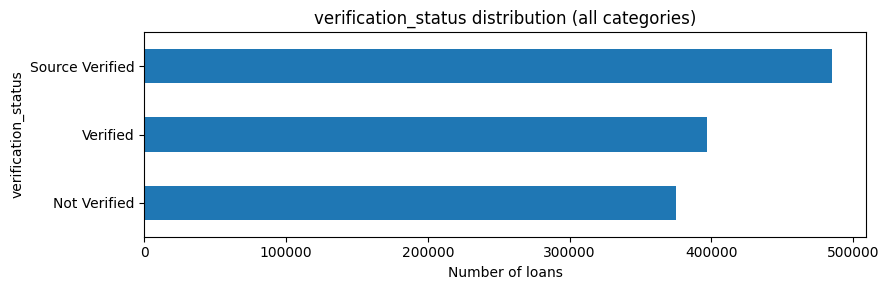

grade: 7 categories


,count
grade,
B,367339
C,357565
A,215654
D,187103
E,88994
F,30938
G,8832


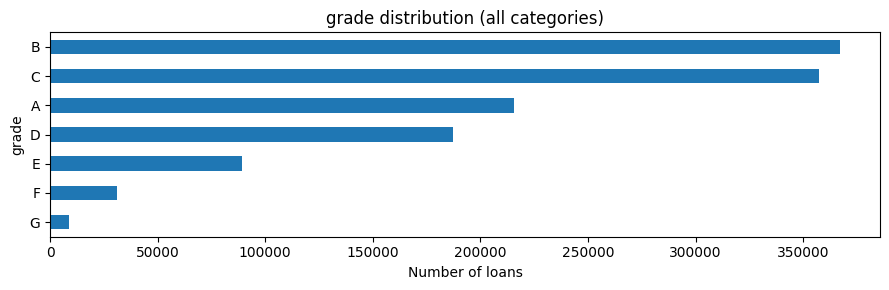

sub_grade: 35 categories


,count
sub_grade,
C1,80183
B4,77949
B3,77253
B5,76807
C2,74393
C3,70207
C4,69604
B2,69103
B1,66227


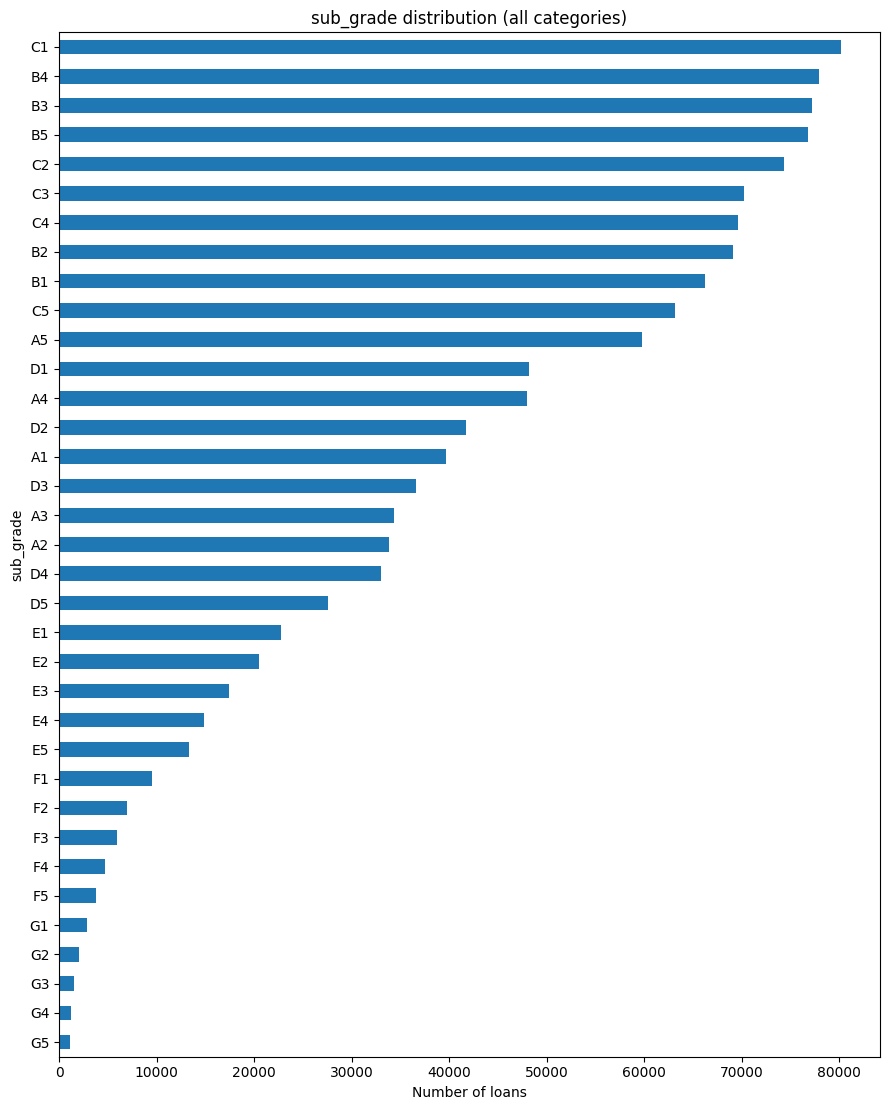

In [ ]:
# Summarise percentiles for all numerical predictors
percentiles = df[numeric].quantile([.01, .25, .5, .75, .95, .99]).T
display(percentiles.round(2))
percentiles.to_csv(OUT / 'numeric_percentiles.csv')

# Plot a histogram for every numerical predictor
for col in numeric:
    values = df[col].dropna()
    if values.empty:
        continue
    lower, upper = values.quantile([.01, .99])
    shown = values.between(lower, upper)
    plt.figure(figsize=(6, 3))
    values[shown].hist(bins=30)
    plt.title(f'{col} distribution (1st–99th percentile)')
    plt.xlabel(col)
    plt.ylabel('Number of loans')
    plt.tight_layout()
    plt.savefig(OUT / f'distribution_{col}.png', dpi=120)
    plt.show()

# Save complete frequency tables and plot every categorical predictor
for col in categorical:
    counts = df[col].fillna('Missing').astype(str).value_counts()
    print(f'{col}: {len(counts)} categories')
    display(counts.to_frame('count'))
    counts.rename_axis(col).to_csv(OUT / f'frequency_{col}.csv')
    counts.sort_values().plot.barh(figsize=(9, max(3, min(18, len(counts) * .32))))
    plt.title(f'{col} distribution (all categories)')
    plt.xlabel('Number of loans')
    plt.tight_layout()
    plt.savefig(OUT / f'distribution_{col}.png', dpi=120)
    plt.show()

## 7. Correlation analysis and loan outcome comparisons

Categorical predictors are not placed in the numerical correlation matrix because their labels are not numerical measurements.

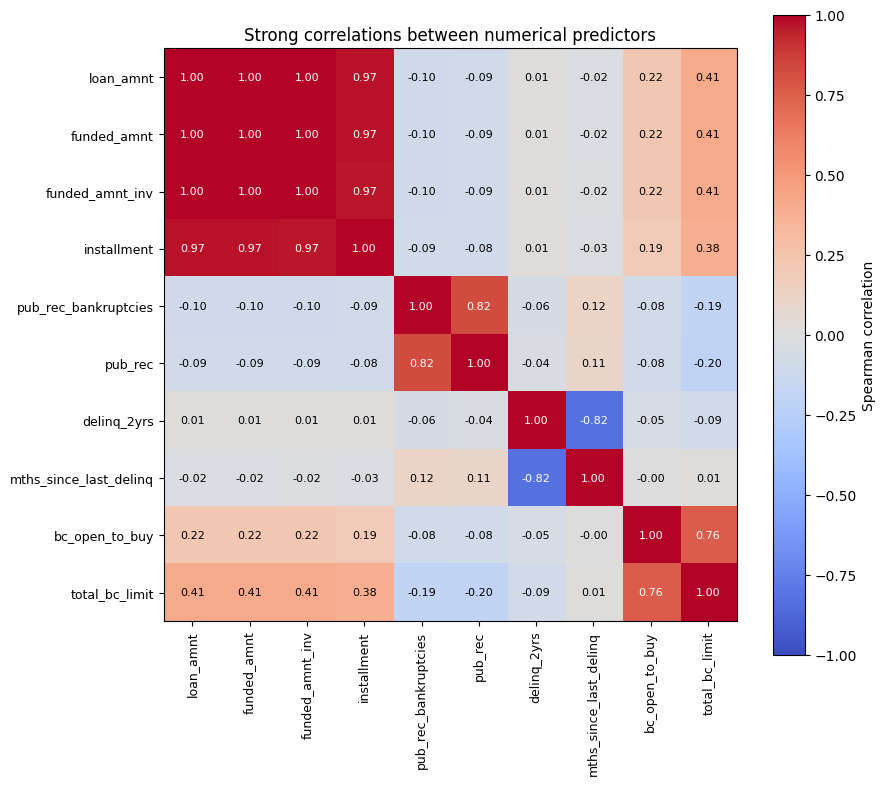

,Feature 1,Feature 2,Spearman
14,loan_amnt,funded_amnt,1.000
285,funded_amnt,funded_amnt_inv,0.999
15,loan_amnt,funded_amnt_inv,0.998
63,installment,funded_amnt,0.970
1,loan_amnt,installment,0.969
64,installment,funded_amnt_inv,0.968
232,pub_rec_bankruptcies,pub_rec,0.823
216,delinq_2yrs,mths_since_last_delinq,-0.822
319,bc_open_to_buy,total_bc_limit,0.760
141,open_acc,total_acc,0.693


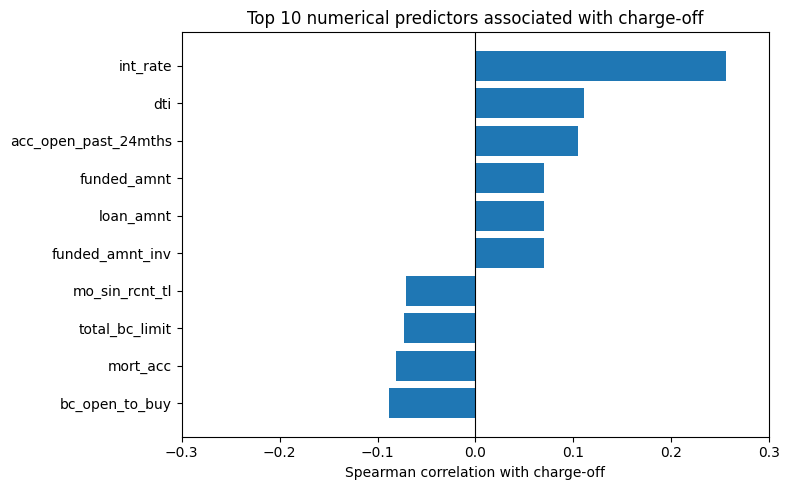

loan_status,Charged Off,Fully Paid
int_rate,15.05,12.29
dti,19.82,17.12
annual_inc,60000.00,65000.00
loan_amnt,14250.00,12000.00
revol_util,56.00,52.00


,count,chargeoff_percent
grade,,
A,215654,6.14
B,367339,13.52
C,357565,22.69
D,187103,30.72
E,88994,38.94
F,30938,45.54
G,8832,50.23


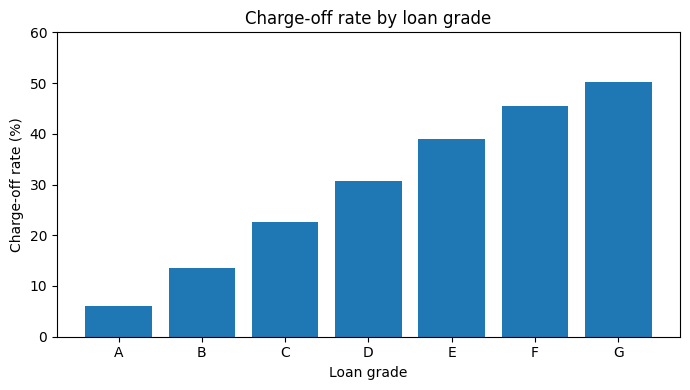

In [ ]:
# Calculate correlations for all numerical predictors
corr = df[numeric].corr(method='spearman')
corr.to_csv(OUT / 'correlations.csv')

# Identify the 10 strongest correlations between numerical predictors
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
pairs = upper.stack().rename('Spearman').reset_index()
pairs.columns = ['Feature 1', 'Feature 2', 'Spearman']
pairs = pairs.sort_values(
    'Spearman', key=lambda s: s.abs(), ascending=False
)

# Select predictors involved in strong correlations (|Spearman| >= 0.75)
strong_pairs = pairs.loc[pairs['Spearman'].abs() >= 0.75]
features = pd.unique(
    strong_pairs[['Feature 1', 'Feature 2']].to_numpy().ravel()
).tolist()

# Plot a focused heatmap of strongly correlated numerical predictors
if len(features) >= 2:
    small_corr = corr.loc[features, features]

    fig, ax = plt.subplots(
        figsize=(max(8, len(features) * 0.9),
                 max(7, len(features) * 0.8))
    )

    image = ax.imshow(small_corr, vmin=-1, vmax=1, cmap='coolwarm')
    ax.set_xticks(range(len(features)))
    ax.set_xticklabels(features, rotation=90, fontsize=9)
    ax.set_yticks(range(len(features)))
    ax.set_yticklabels(features, fontsize=9)

    # Display correlation coefficients inside each box
    for row in range(len(features)):
        for col in range(len(features)):
            value = small_corr.iloc[row, col]
            if pd.notna(value):
                text_color = 'white' if abs(value) >= 0.6 else 'black'
                ax.text(
                    col, row, f'{value:.2f}',
                    ha='center', va='center',
                    fontsize=8, color=text_color
                )

    fig.colorbar(image, ax=ax, label='Spearman correlation')
    ax.set_title('Strong correlations between numerical predictors')
    fig.tight_layout()
    fig.savefig(OUT / 'strong_feature_correlations.png', dpi=200)
    plt.show()

# Display the 10 strongest feature-pair correlations
display(pairs.head(10).round(3))
pairs.to_csv(OUT / 'feature_pair_correlations.csv', index=False)

# Compare every numerical predictor with the binary target
target_corr = df[numeric + ['target']].corr(method='spearman')['target'].drop('target')
target_corr = target_corr.reindex(
    target_corr.abs().sort_values(ascending=False).index
)
target_corr.to_csv(
    OUT / 'target_correlations.csv',
    header=['spearman_with_target']
)

# Plot the 10 numerical predictors most correlated with loan outcomes
top_target = target_corr.head(10).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top_target.index, top_target.values)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlim(-0.3, 0.3)
ax.set_xlabel('Spearman correlation with charge-off')
ax.set_title('Top 10 numerical predictors associated with charge-off')
fig.tight_layout()
fig.savefig(OUT / 'top_target_correlations.png', dpi=200)
plt.show()

# Compare numerical medians across loan outcomes
medians = df.groupby('loan_status')[numeric].median().T
medians.to_csv(OUT / 'medians_by_outcome.csv')

# Display selected numerical medians for both loan outcomes
selected = ['int_rate', 'dti', 'annual_inc', 'loan_amnt', 'revol_util']
display(medians.loc[selected].round(2))

# Compare charge-off rates across every categorical predictor
for col in categorical:
    result = df.groupby(col, dropna=False)['target'].agg(['count', 'mean'])
    result['chargeoff_percent'] = result['mean'] * 100
    result[['count', 'chargeoff_percent']].to_csv(
        OUT / f'chargeoff_by_{col}.csv'
    )

# Compare charge-off rates across loan grades
grade_rates = df.groupby('grade', dropna=False)['target'].agg(['count', 'mean'])
grade_rates = grade_rates.reindex(list('ABCDEFG'))
grade_rates['chargeoff_percent'] = grade_rates['mean'] * 100

# Display loan counts and charge-off percentages by grade
display(grade_rates[['count', 'chargeoff_percent']].round(2))

# Plot charge-off percentages across loan grades
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(grade_rates.index, grade_rates['chargeoff_percent'])
ax.set_xlabel('Loan grade')
ax.set_ylabel('Charge-off rate (%)')
ax.set_ylim(0, 60)
ax.set_title('Charge-off rate by loan grade')
fig.tight_layout()
fig.savefig(OUT / 'chargeoff_by_grade.png', dpi=200)
plt.show()


## 8. Outlier analysis
Calculate IQR-based outlier counts for **all numerical candidate predictors** and show a boxplot for each. IQR flags unusual values, not necessarily errors. Results for discrete counts and highly skewed features require careful interpretation. No outliers are removed.

,attribute,outlier_count,outlier_percent,lower_bound,upper_bound
0,loan_amnt,4797,0.38,-10000.00,38000.00
1,int_rate,22173,1.76,0.39,25.35
2,installment,39153,3.12,-244.17,1072.44
3,annual_inc,60433,4.81,-20632.50,156379.50
4,dti,3916,0.31,-6.44,42.32
5,inq_last_6mths,68510,5.45,-1.50,2.50
6,open_acc,42511,3.38,-1.00,23.00
7,total_acc,20984,1.67,-8.00,56.00
8,revol_util,67,0.01,-21.15,126.45
9,revol_bal,73943,5.89,-14689.50,40538.50


Negative DTI: 2
Nonpositive income: 191
Revolving utilisation above 100%: 4449


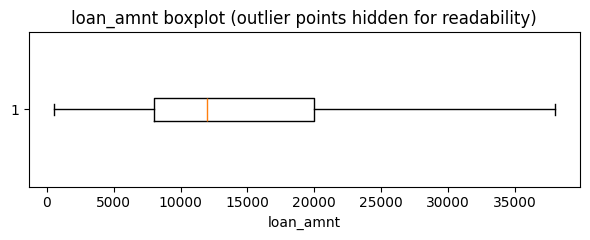

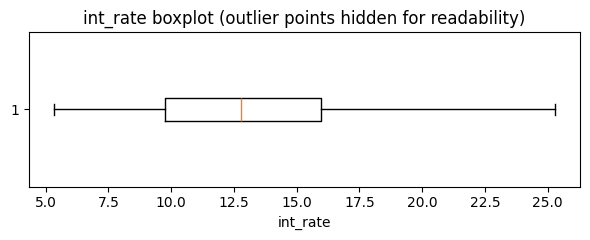

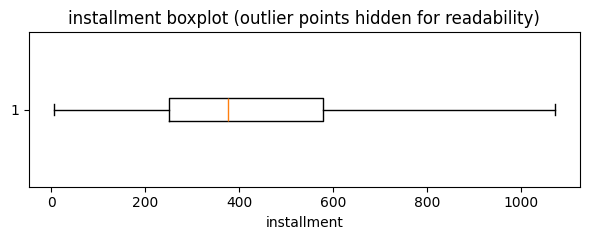

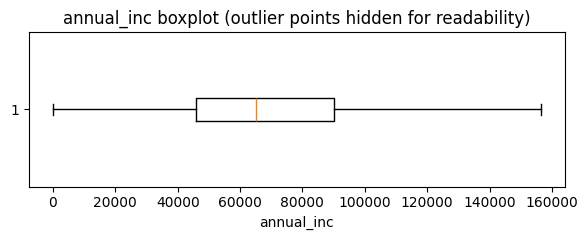

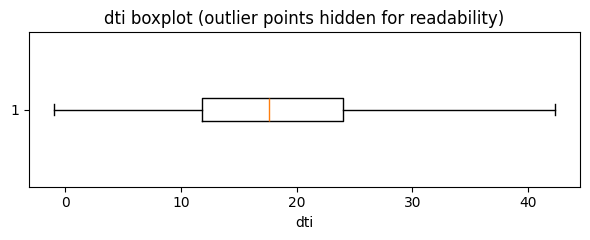

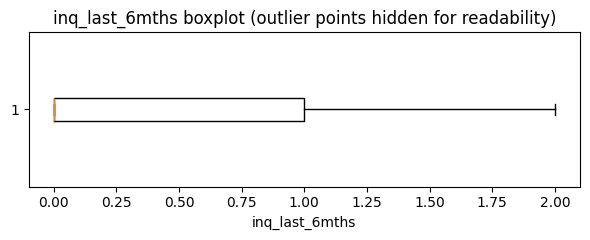

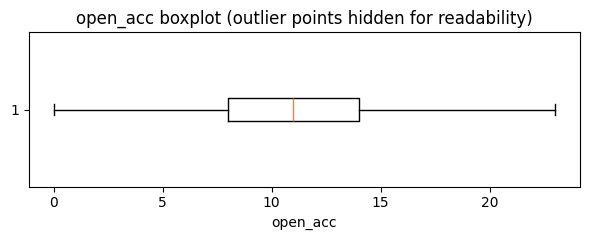

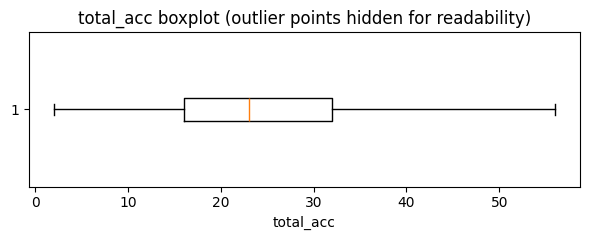

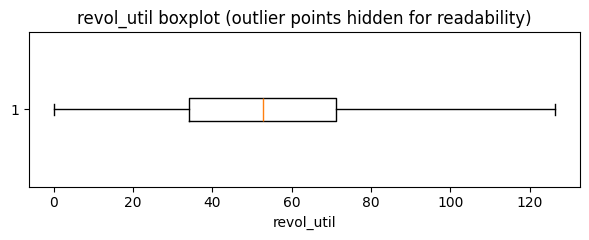

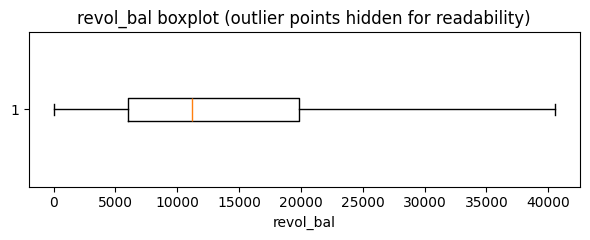

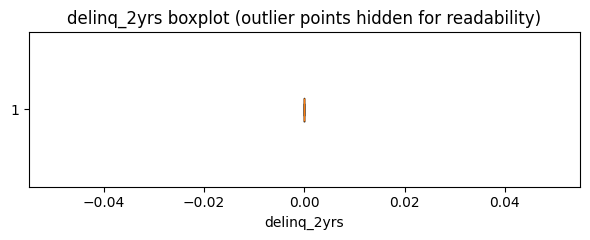

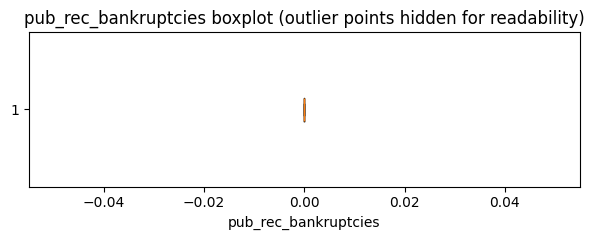

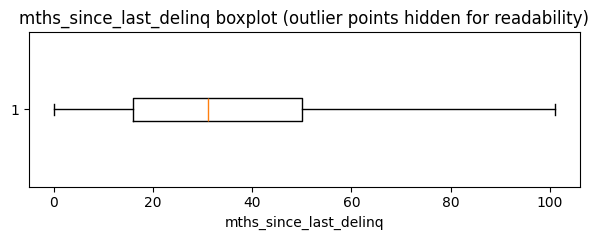

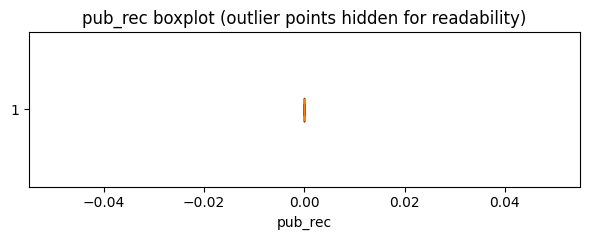

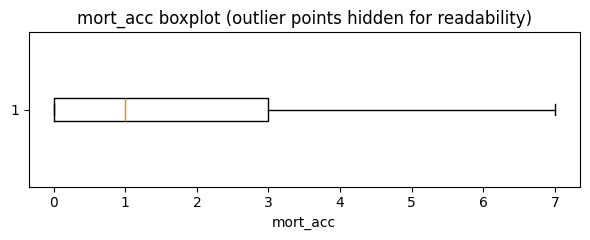

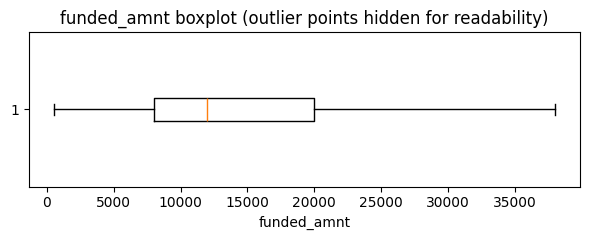

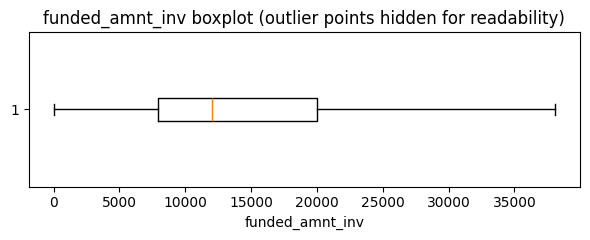

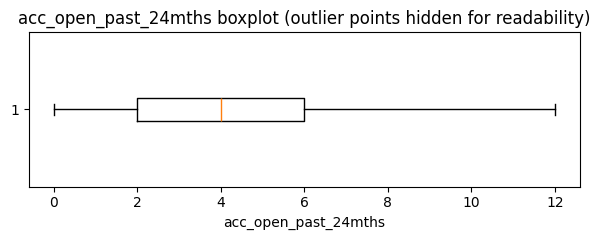

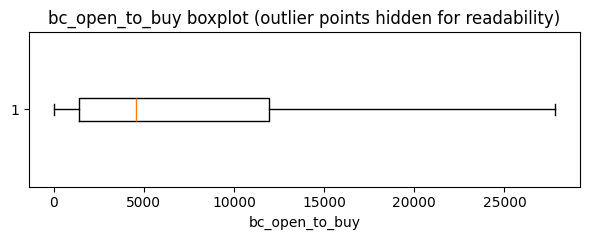

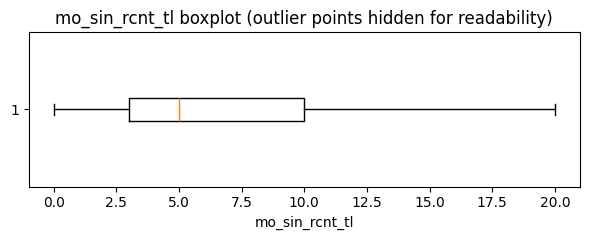

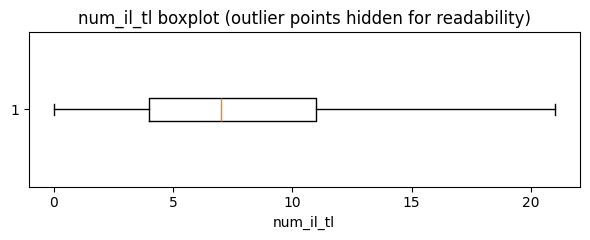

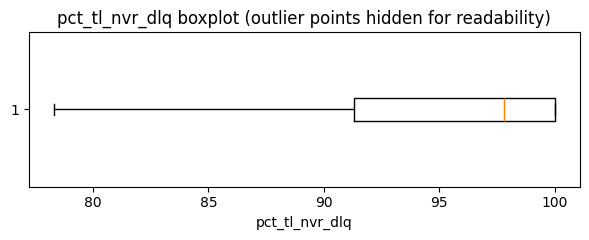

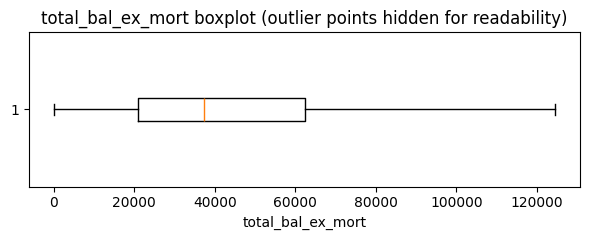

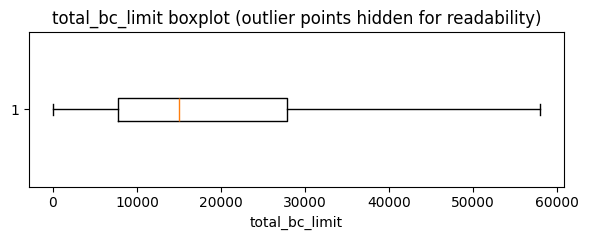

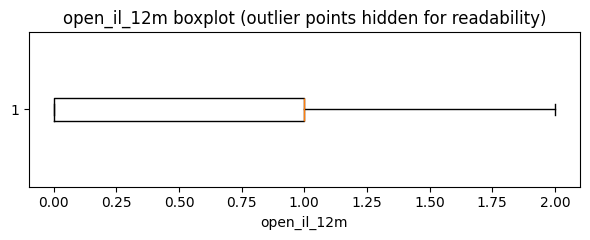

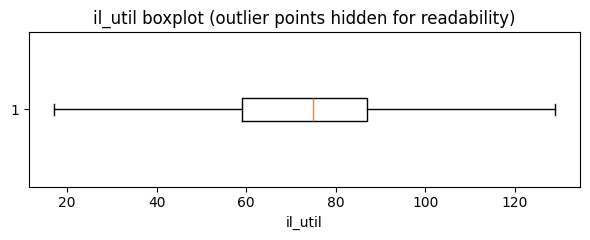

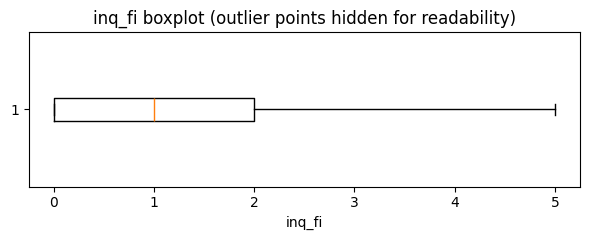

In [ ]:
# Calculate IQR outlier counts for every numerical predictor
outlier_results = []
for col in numeric:
    values = df[col].dropna()
    if values.empty:
        outlier_results.append([col, 0, 0, None, None])
        continue
    q1, q3 = values.quantile([.25, .75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    flagged = ((values < lower) | (values > upper)).sum()
    outlier_results.append([col, int(flagged), flagged / len(values) * 100, lower, upper])

outliers = pd.DataFrame(outlier_results, columns=[
    'attribute', 'outlier_count', 'outlier_percent', 'lower_bound', 'upper_bound'
])
display(outliers.round(2))
outliers.to_csv(OUT / 'outliers.csv', index=False)

# Check potentially invalid values
print('Negative DTI:', (df['dti'] < 0).sum())
print('Nonpositive income:', (df['annual_inc'] <= 0).sum())
print('Revolving utilisation above 100%:', (df['revol_util'] > 100).sum())

# Plot a boxplot for every numerical predictor
for col in numeric:
    values = df[col].dropna()
    if values.empty:
        continue
    plt.figure(figsize=(6, 2.5))
    plt.boxplot(values, vert=False, showfliers=False)
    plt.title(f'{col} boxplot (outlier points hidden for readability)')
    plt.xlabel(col)
    plt.tight_layout()
    plt.savefig(OUT / f'boxplot_{col}.png', dpi=120)
    plt.show()